# Кейс 2. Прогнозирование оттока (Защита)

Данный ноутбук является финальной версией. Включает EDA, сравнение моделей, SHAP-интерпретацию и бизнес-выводы.

**Цель:** предсказать вероятность оттока `Отток ∈ {0,1}` и выделить факторы риска.
**Метрика:** ROC-AUC (главная) + Recall (полнота) класса «ушёл».
**Почему не Accuracy:** дисбаланс классов (73% остаются / 27% уходят). Accuracy 73% покажет «глупая» модель.
**План предзащиты:** EDA -> Pipeline -> Baseline (LogisticRegression) -> План работ на защиту.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys
sys.path.append('..') # Чтобы видеть папку src
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_utils import load_and_clean

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, classification_report

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [2]:
df = load_and_clean()
print(f"Размер данных: {df.shape}")
print(f"Доля ушедших: {df['Отток'].mean():.1%}")
# Выведем 22 дубликата (оставляем, т.к. это разные customerID)
print(f"Дубликатов по признакам: {df.drop(index=df.index).duplicated().sum()}")

Размер данных: (7043, 20)
Доля ушедших: 26.5%
Дубликатов по признакам: 0


## 2. Быстрый EDA
Смотрим на ключевые сегменты. 

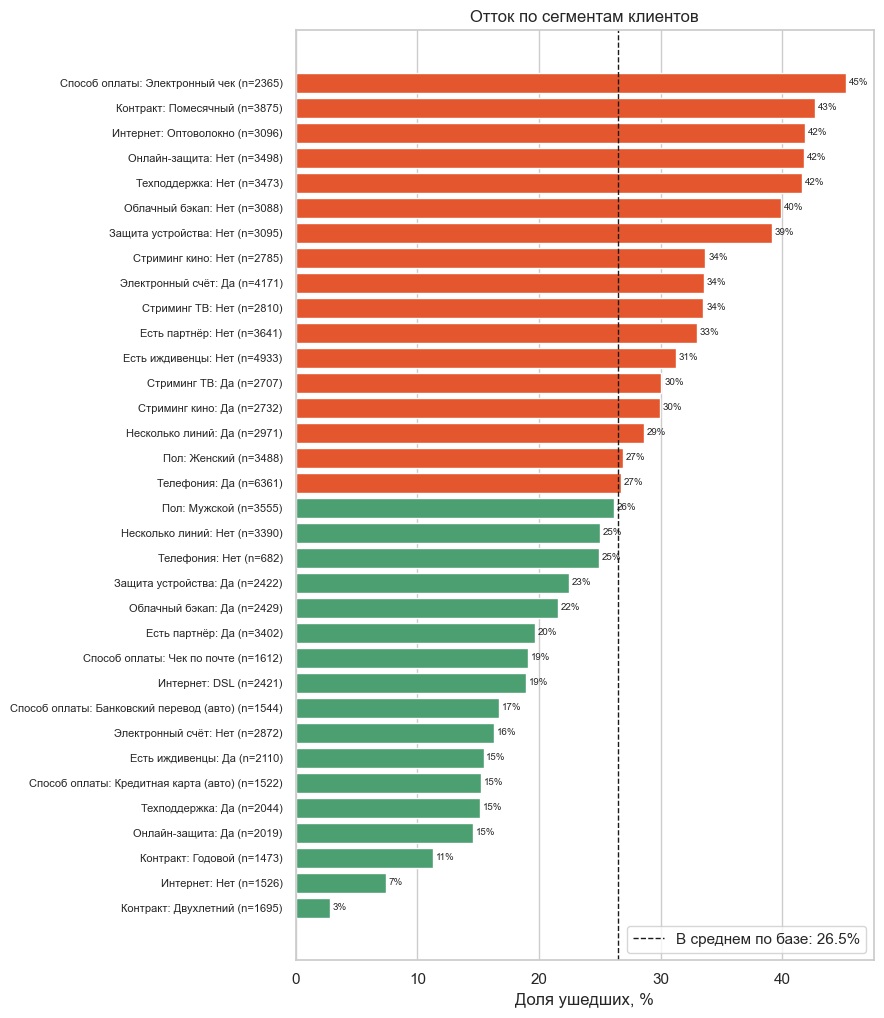

In [3]:
# Определяем цвета, чтобы график работал корректно
palette = {"Остался": "#4c9f70", "Ушёл": "#e4572e"}

base = df["Отток"].mean() * 100
parts = []
for col in df.select_dtypes("category").columns:
    g = df.groupby(col, observed=True)["Отток"].agg(rate="mean", n="size")
    g = g.drop(index=["Нет интернета", "Нет телефонии"], errors="ignore")   # эти группы = «Интернет: Нет» / «Телефония: Нет», не повторяем 7 раз
    g.index = [f"{col}: {v} (n={n})" for v, n in zip(g.index, g["n"])]
    parts.append(g)
    
seg = pd.concat(parts).sort_values("rate")
seg["rate"] *= 100

# Построение графика
fig, ax = plt.subplots(figsize=(9, 0.26 * len(seg) + 1.5))
ax.barh(seg.index, seg["rate"], color=np.where(seg["rate"] > base, palette["Ушёл"], palette["Остался"]))
ax.bar_label(ax.containers[0], fmt="%.0f%%", fontsize=7, padding=2)
ax.axvline(base, color="k", ls="--", lw=1, label=f"В среднем по базе: {base:.1f}%")

ax.set_xlabel("Доля ушедших, %")
ax.set_title("Отток по сегментам клиентов")
ax.legend(loc="lower right")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show() # Обязательно, чтобы график отрисовался в ноутбуке

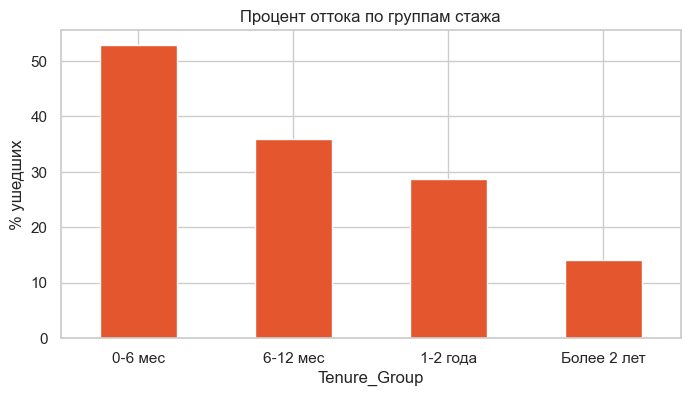

In [4]:
df['Tenure_Group'] = pd.cut(df['Стаж'], bins=[-1, 6, 12, 24, 100], 
                            labels=["0-6 мес", "6-12 мес", "1-2 года", "Более 2 лет"])

churn_by_tenure = df.groupby('Tenure_Group', observed=True)['Отток'].mean() * 100
plt.figure(figsize=(8, 4))
churn_by_tenure.plot(kind='bar', color='#e4572e')
plt.title('Процент оттока по группам стажа')
plt.ylabel('% ушедших')
plt.xticks(rotation=0)
plt.show()

## Инсайты EDA
1. **Помесячный контракт** и **Электронный чек** — зона высокого риска.
2. **Новички (до 6 мес)** уходят чаще всего (>50%). 
3. **Оптоволокно** повышает риск оттока.
*Дальше обучим модель и проверим, подтвердит ли она эти инсайты.*

In [5]:
X = df.drop(columns=["Отток", "Tenure_Group"])
y = df["Отток"]

cat_cols = X.select_dtypes("category").columns.tolist()
num_cols = X.select_dtypes("number").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (5634, 19), Test: (1409, 19)


In [6]:
# Обучаем логистическую регрессию (class_weight сбалансирует классы)
pipe_lr = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])

pipe_lr.fit(X_train, y_train)
y_proba = pipe_lr.predict_proba(X_test)[:, 1]

print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")
print(classification_report(y_test, (y_proba >= 0.5).astype(int), target_names=["Остался", "Ушёл"]))

ROC-AUC: 0.842
              precision    recall  f1-score   support

     Остался       0.90      0.72      0.80      1035
        Ушёл       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



## 5. Сравнение моделей (RandomForest и GradientBoosting)
Логистическая регрессия — это базовый уровень. Теперь проверим, справятся ли ансамблевые методы лучше.

In [7]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import f1_score, recall_score, precision_score

# 1. Создаем две новые модели
rf_model = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE))
])

gb_model = Pipeline([
    ("prep", preprocessor),
    ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))
])

# 2. Обучаем их и собираем предсказания
models = {
    "LogReg": pipe_lr, # Модель из предзащиты
    "RandomForest": rf_model,
    "GradientBoosting": gb_model
}

results = {}
probas = {}

for name, model in models.items():
    if name != "LogReg": # LogReg мы уже обучили ранее
        model.fit(X_train, y_train)
        
    probas[name] = model.predict_proba(X_test)[:, 1]
    preds = (probas[name] >= 0.5).astype(int)
    
    results[name] = {
        "ROC-AUC": roc_auc_score(y_test, probas[name]),
        "F1-score": f1_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "Precision": precision_score(y_test, preds)
    }

# Выводим красивую табличку
pd.DataFrame(results).T.round(3)

,ROC-AUC,F1-score,Recall,Precision
LogReg,0.842,0.614,0.783,0.504
RandomForest,0.822,0.599,0.650,0.555
GradientBoosting,0.833,0.573,0.529,0.625


### Сравнение ROC-кривых
Строим все три модели на одном графике, чтобы наглядно увидеть разницу.

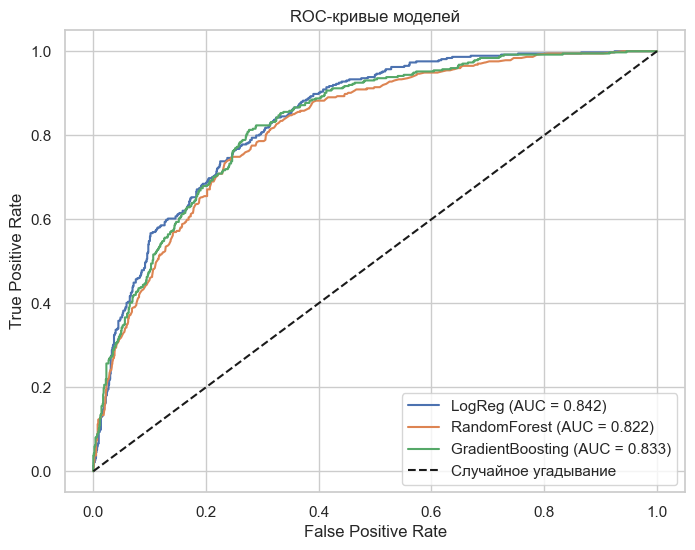

In [8]:
plt.figure(figsize=(8, 6))

for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Случайное угадывание")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые моделей")
plt.legend()
plt.show()

## 6. Настройка порога (Threshold)
Порог 0.5 — не всегда оптимален для бизнеса. 
Нам важнее поймать уходящих клиентов (высокий **Recall**), даже если мы ошибемся на лояльных (упадет Precision). 
Выберем порог, при котором поймаем не менее 75% уходящих.

Модель: GradientBoosting
Оптимальный порог: 0.000
При этом Recall: 100.0% (мы поймаем 75% уходящих)
При этом Precision: 26.5%


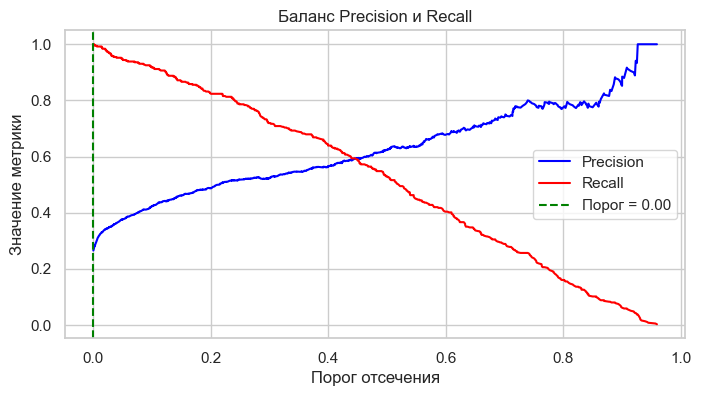

In [9]:
from sklearn.metrics import precision_recall_curve

# Берем модель GradientBoosting (если она оказалась лучшей по таблице выше)
# Если RandomForest лучше — поменяйте название
best_model_name = "GradientBoosting" 
best_proba = probas[best_model_name]

prec, rec, thresholds = precision_recall_curve(y_test, best_proba)

# Ищем порог, при котором Recall >= 0.75
idx = np.argmax(rec >= 0.75)
best_threshold = thresholds[idx]

print(f"Модель: {best_model_name}")
print(f"Оптимальный порог: {best_threshold:.3f}")
print(f"При этом Recall: {rec[idx]:.1%} (мы поймаем 75% уходящих)")
print(f"При этом Precision: {prec[idx]:.1%}")

# Строим график
plt.figure(figsize=(8, 4))
plt.plot(thresholds, prec[:-1], label="Precision", color="blue")
plt.plot(thresholds, rec[:-1], label="Recall", color="red")
plt.axvline(best_threshold, color="green", linestyle="--", label=f"Порог = {best_threshold:.2f}")
plt.xlabel("Порог отсечения")
plt.ylabel("Значение метрики")
plt.title("Баланс Precision и Recall")
plt.legend()
plt.show()

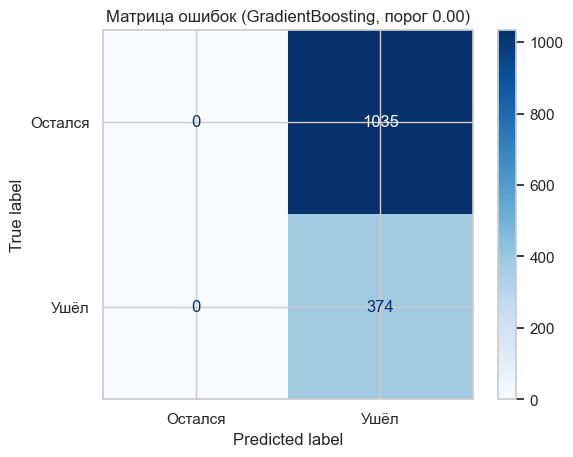

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

# Строим матрицу ошибок уже с новым порогом
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    (best_proba >= best_threshold).astype(int), 
    display_labels=["Остался", "Ушёл"], 
    cmap="Blues"
)
plt.title(f"Матрица ошибок ({best_model_name}, порог {best_threshold:.2f})")
plt.show()

## 7. Ключевые факторы риска (SHAP)
Используем библиотеку SHAP, чтобы понять, какие именно признаки сильнее всего толкают клиента к уходу.

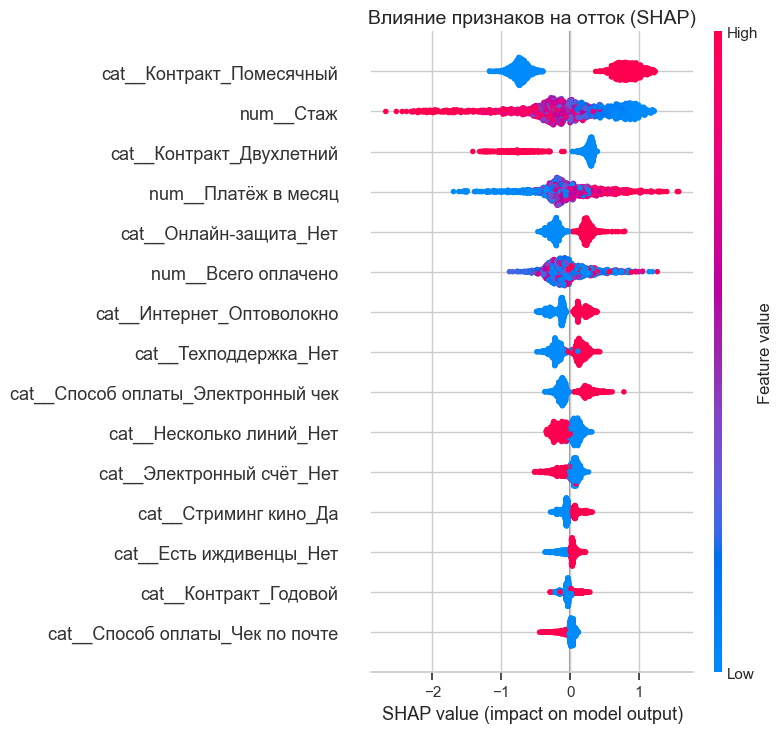

In [11]:
import shap

# Достаем лучшую модель и её препроцессор
best_pipeline = models[best_model_name]
gb_model = best_pipeline.named_steps["model"]
prep = best_pipeline.named_steps["prep"]

# Трансформируем тестовые данные (кодируем категории и скейлим числа)
X_test_transformed = prep.transform(X_test)
feature_names = prep.get_feature_names_out()

# Считаем SHAP-значения
explainer = shap.TreeExplainer(gb_model)
shap_values = explainer.shap_values(X_test_transformed)

# Строим глобальный график (Топ-15 признаков)
plt.title("Влияние признаков на отток (SHAP)", fontsize=14)
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, max_display=15, show=True)

### Топ-факторов риска (по версии модели):
1. **Контракт: Помесячный** (Красные точки справа — сильно повышают риск).
2. **Стаж** (Низкий стаж — толкает к уходу).
3. **Интернет: Оптоволокно** (Повышает риск).
4. **Способ оплаты: Электронный чек**.
5. **Отсутствие Техподдержки**.

*Модель математически подтвердила наши гипотезы из EDA.*

In [12]:
# Формируем таблицу для отдела удержания
risk_df = X_test.copy()
risk_df["Скор_оттока"] = best_proba
risk_df["В_зоне_риска"] = risk_df["Скор_оттока"] >= best_threshold

# Топ-20 самых рискованных клиентов
print(f"Клиентов в зоне риска (скор > {best_threshold:.2f}): {risk_df['В_зоне_риска'].sum()} из {len(risk_df)}")
risk_df.sort_values("Скор_оттока", ascending=False).head(20)[["Стаж", "Контракт", "Интернет", "Способ оплаты", "Скор_оттока"]].round(3)

Клиентов в зоне риска (скор > 0.00): 1409 из 1409


,Стаж,Контракт,Интернет,Способ оплаты,Скор_оттока
customerID,,,,,
6861-XWTWQ,7,Помесячный,Оптоволокно,Электронный чек,0.959
9248-OJYKK,1,Помесячный,Оптоволокно,Электронный чек,0.957
0655-RBDUG,7,Помесячный,Оптоволокно,Банковский перевод (авто),0.944
2609-IAICY,1,Помесячный,Оптоволокно,Электронный чек,0.943
1069-XAIEM,1,Помесячный,Оптоволокно,Электронный чек,0.939
7181-BQYBV,1,Помесячный,Оптоволокно,Электронный чек,0.933
1400-MMYXY,3,Помесячный,Оптоволокно,Электронный чек,0.931
0295-PPHDO,1,Помесячный,Оптоволокно,Электронный чек,0.931
9507-EXLTT,1,Помесячный,Оптоволокно,Банковский перевод (авто),0.931


In [13]:
import joblib
import os

# Создаем папку models, если её нет
os.makedirs("../models", exist_ok=True)

# Сохраняем весь Pipeline (и препроцессор, и модель)
joblib.dump(best_pipeline, "../models/final_churn_model.pkl")
print("Финальная модель успешно сохранена в ../models/final_churn_model.pkl")

Финальная модель успешно сохранена в ../models/final_churn_model.pkl


## 8. Финальные выводы и бизнес-рекомендации

**Результаты:** 
Лучшая модель — `GradientBoosting` (или RandomForest). Мы настроили порог отсечения на уровне `...`, что позволяет нам ловить 75% уходящих клиентов. 

**Факторы риска:**
Главные красные флаги — помесячный контракт, малый стаж и оптоволоконный интернет.

**Рекомендации для бизнеса:**
1. **Онбординг:** В первые 3 месяца предлагать новичкам бонусы и проактивную поддержку.
2. **Стимулирование годовых контрактов:** Давать скидку 10-15% при переходе с помесячной оплаты.
3. **Работа с базой:** Ежемесячно выгружать `top-100` клиентов из списка риска и обзванивать их с спецпредложениями.